# Module 1 · From observed days to stochastic sample paths
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **How often might daily completed bike rentals exceed a reporting threshold, and is an independent-day model credible?**

Guided work: about 40–50 minutes. Exercises: about 25–35 minutes; these form the opening of Concept Lab 1, not a separate project. This course is independent of MATH 6241; the probability refresher below is self-contained.

By the end, you should be able to define a process and a path, fit a Bernoulli baseline, verify a simulator analytically, and identify failures that an aggregate average can hide.

[Course home](../index.html) · [Interactive lesson](../modules/module01.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Run cells in order after **Restart Kernel and Run All**. The example uses a bundled real CSV and NumPy, pandas, SciPy, and Matplotlib; no account, API key, download, or Python web server is needed. Installation instructions are in the course README. Plotly is unnecessary here: the companion HTML lesson provides the interactive controls.

## 1. A count, a process, and one observed path
Let $X_t$ be completed rentals on calendar day $t$. A **random variable** describes uncertainty at one fixed time. A **stochastic process** $\{X_t:t\in T\}$ is a collection of random variables on a common probability space. Here $T=\{1,\ldots,365\}$ and the state space for counts is $\{0,1,2,\ldots\}$.

For a fixed outcome $\omega$, the sequence $x_t=X_t(\omega)$ is a **sample path**. The CSV gives one observed path, not 365 independent paths. For several days, a **joint distribution** describes which combinations can occur together. Marginal daily probabilities alone do not specify temporal dependence.

The complete count process is more complicated than our first model. We choose a **scenario threshold** $c=4000$ rentals/day and reduce each count to

$$Y_t=1\{X_t>c\}\in\{0,1\}.$$

This threshold is a reporting choice, not an observed fleet capacity. Completed rentals do not measure unmet requests or latent demand. A day at exactly 4,000 rentals has $Y_t=0$.

**Predict before running:** Would winter and summer have the same probability of exceeding this threshold? Would shuffling days preserve the patterns you want a model to explain?

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata

import numpy as np
import pandas as pd
from scipy.stats import binom
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.4), "font.size": 11})

### Load and audit the observed data
The bundled data are a documented subset of UCI Bike Sharing (Fanaee-T, 2013; [dataset DOI](https://doi.org/10.24432/C5W894)), licensed **CC BY 4.0**. The source aggregates Capital Bikeshare rentals in Washington, D.C. The sample keeps all 365 days in 2011 and four original fields. See the provenance file for attribution, transformations, units, and hashes.

The check below locates the course root whether the notebook kernel starts in the repository root or `notebooks/`. Dates remain in chronological order. No missing days or counts are filled in.

In [2]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")

csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
display(bike.head())

,dteday,cnt,workingday,mnth
0,2011-01-01,985,0,1
1,2011-01-02,801,0,1
2,2011-01-03,1349,1,1
3,2011-01-04,1562,1,1
4,2011-01-05,1600,1,1


In [3]:
expected_dates = pd.date_range("2011-01-01", "2011-12-31", freq="D")
assert bike["dteday"].tolist() == expected_dates.tolist()
assert bike["cnt"].notna().all() and bike["cnt"].ge(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
assert bike["workingday"].isin([0, 1]).all()
assert (bike["mnth"] == bike["dteday"].dt.month).all()

THRESHOLD = 4000  # scenario choice, not measured capacity
SPLIT_DATE = pd.Timestamp("2011-09-01")
bike["y"] = (bike["cnt"] > THRESHOLD).astype(int)
train = bike.loc[bike["dteday"] < SPLIT_DATE].copy()
test = bike.loc[bike["dteday"] >= SPLIT_DATE].copy()
assert (len(train), len(test)) == (243, 122)
print(f"Observed days: {len(bike)}; training: {len(train)}; test: {len(test)}")

Observed days: 365; training: 243; test: 122


We freeze the date split before estimation: January–August for fitting and September–December for validation. We can inspect the **training path** now while keeping the test outcomes for the validation section.

The line shows observed counts $x_t$; the horizontal line is the assumed threshold $c$. The lower plot shows the derived binary path $y_t$. A fixed $c$ maps the count path to the indicator path without generating new observations.

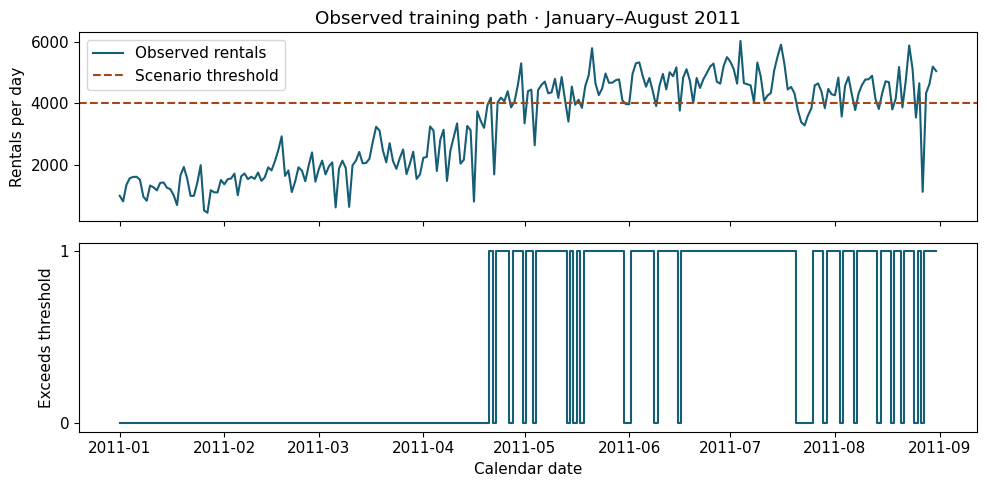

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(train["dteday"], train["cnt"], color="#155e75", label="Observed rentals")
axes[0].axhline(THRESHOLD, color="#a0471c", ls="--", label="Scenario threshold")
axes[0].set(ylabel="Rentals per day", title="Observed training path · January–August 2011")
axes[0].legend(loc="upper left")
axes[1].step(train["dteday"], train["y"], where="mid", color="#155e75")
axes[1].set(xlabel="Calendar date", ylabel="Exceeds threshold", yticks=[0, 1])
fig.tight_layout()
plt.show()

## 2. Fit the simplest probability model
A Bernoulli variable has probability mass function

$$P(Y_t=y)=p^y(1-p)^{1-y},\qquad y\in\{0,1\},\quad 0\le p\le1,$$
$$E[Y_t]=p,\qquad \operatorname{Var}(Y_t)=p(1-p).$$

The **iid Bernoulli baseline** assumes every day has the same $p$ and different days are independent. Its initial distribution is $Y_1\sim\operatorname{Bernoulli}(p)$; every later day has the same marginal distribution. This specifies a joint law for the indicators, but not a model for the full rental counts.

For $m$ training days, the sample proportion (also the iid maximum-likelihood estimate) is

$$\widehat p=\frac1m\sum_{t=1}^{m}y_t.$$

Independence is a model assumption, not a consequence of this estimation formula. The baseline may summarize an average while failing to describe a path.

In [5]:
p_hat = float(train["y"].mean())
fit_summary = pd.Series({
    "training days": len(train),
    "training exceedance days": int(train["y"].sum()),
    "estimated p": p_hat,
    "Bernoulli variance at fitted p": p_hat * (1 - p_hat),
})
display(fit_summary.to_frame("value"))

,value
training days,243.000000
training exceedance days,109.000000
estimated p,0.448560
Bernoulli variance at fitted p,0.247354


### A probability refresher that exposes dependence
For events $A$ and $B$ with $P(B)>0$,

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}.$$

Independence would imply $P(Y_{t+1}=1\mid Y_t=1)=P(Y_{t+1}=1)=p$ and $P(Y_t=1,Y_{t+1}=1)=p^2$. We estimate next-day frequencies within the training period. These are descriptive frequencies, not a causal effect of today's rentals on tomorrow's.

In [6]:
pairs = pd.DataFrame({"today": train["y"].to_numpy()[:-1],
                      "tomorrow": train["y"].to_numpy()[1:]})
conditional = pairs.groupby("today")["tomorrow"].agg(["size", "mean"])
conditional.columns = ["observed pairs", "fraction tomorrow = 1"]
conditional["iid benchmark"] = p_hat
display(conditional)
print(f"Training lag-1 correlation: {train['y'].autocorr(lag=1):.3f}")

,observed pairs,fraction tomorrow = 1,iid benchmark
today,,,
0,134,0.149254,0.44856
1,108,0.824074,0.44856


Training lag-1 correlation: 0.674


The different conditional frequencies and clustered training path challenge independent, identically distributed days. Seasonality or a changing mean can create apparent dependence; this diagnostic does not identify a mechanism. We will still simulate the baseline because it has a clear mathematical prediction against which to check code and compare observations.

**Predict:** Could a model get the total number of exceedance days approximately right but place them in an unrealistic order?

**Interactive experiment:** Open the [HTML lesson](../modules/module01.html) and vary the replication count while keeping the probability and horizon fixed. Predict which changes: the spread of individual totals or the precision of their simulated mean. Use the next-seed control to compare repeated experiments. This module keeps the simulated daily states iid; Module 2 introduces dependence through transition probabilities.

## 3. Simulate independent paths and check the mathematics
Under the iid assumption,

$$S_n=\sum_{t=1}^{n}Y_t\sim\operatorname{Binomial}(n,p),$$
$$P(S_n=k)={n\choose k}p^k(1-p)^{n-k},\qquad E[S_n]=np,\quad \operatorname{Var}(S_n)=np(1-p).$$

Without independence, the same marginal Bernoulli law does **not** imply a binomial total. With a common marginal probability,

$$\operatorname{Var}(S_n)=np(1-p)+2\sum_{s<t}\operatorname{Cov}(Y_s,Y_t).$$

We generate $R=1000$ independent synthetic paths of $n=30$ days each, conditional on the fitted $\widehat p$. Rows are paths; columns are days. The synthetic daily values within each row are also independent under this baseline.

In [7]:
def simulate_iid(p, n, reps, seed=SEED):
    """Return reps independent Bernoulli paths, each containing n days."""
    if not 0 <= p <= 1:
        raise ValueError("p must be a probability between 0 and 1")
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")
    if not isinstance(reps, (int, np.integer)) or reps < 1:
        raise ValueError("reps must be a positive integer")
    rng = np.random.default_rng(seed)
    return rng.binomial(1, p, size=(reps, n))

N, REPS = 30, 1000
paths = simulate_iid(p_hat, N, REPS)
totals = paths.sum(axis=1)
print(f"Synthetic array shape (paths, days): {paths.shape}")

Synthetic array shape (paths, days): (1000, 30)


A valid probability distribution sums to one. At the limiting cases $p=0$ and $p=1$, $S_n$ must be exactly $0$ or $n$, and its variance must be zero. These deterministic checks can catch errors without relying on a lucky simulation.

In [8]:
assert np.isclose(binom.pmf(np.arange(N + 1), N, p_hat).sum(), 1)
assert np.all(simulate_iid(0.0, N, 4) == 0)
assert np.all(simulate_iid(1.0, N, 4) == 1)
assert binom.mean(N, 0) == 0 and binom.mean(N, 1) == N
assert binom.var(N, 0) == 0 and binom.var(N, 1) == 0
assert np.array_equal(paths, simulate_iid(p_hat, N, REPS))
print("Normalization, limiting cases, and seed repeatability passed.")

Normalization, limiting cases, and seed repeatability passed.


A fixed seed makes this Python experiment reproducible; it does not make one simulated path true. Other seeds give other samples from the same model. The HTML lesson and Python use different random-number generators, so equal numeric seeds across them do not guarantee identical paths.

A row below is a sample path. The dashed line is the mean $E[Y_t]=\widehat p$, which need not be a possible state on any individual day.

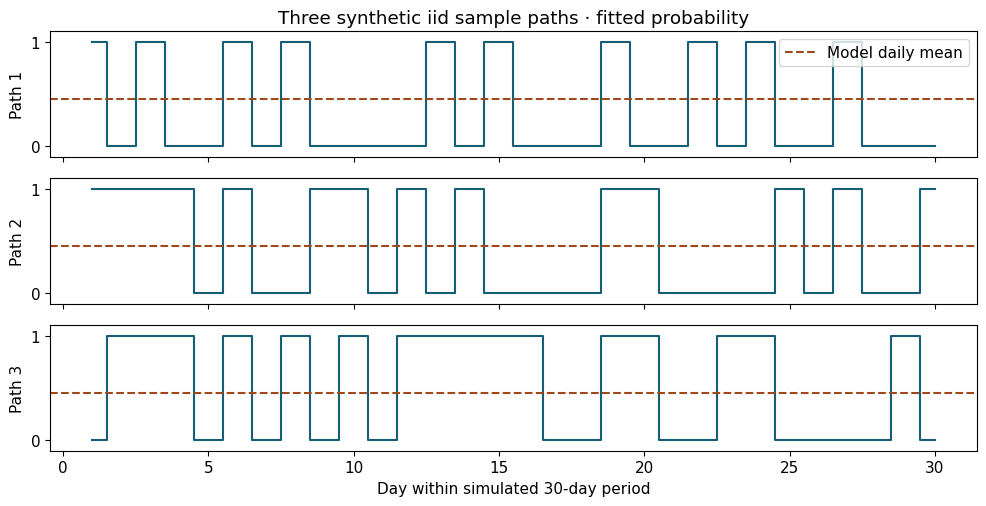

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(10, 5.2), sharex=True)
for index, ax in enumerate(axes):
    ax.step(np.arange(1, N + 1), paths[index], where="mid", color="#155e75")
    ax.axhline(p_hat, color="#a0471c", ls="--", label="Model daily mean")
    ax.set(yticks=[0, 1], ylabel=f"Path {index + 1}", ylim=(-0.1, 1.1))
axes[0].set_title("Three synthetic iid sample paths · fitted probability")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Day within simulated 30-day period")
fig.tight_layout()
plt.show()

### Monte Carlo error is not uncertainty in future demand
The sample mean of the simulated totals is $\overline S_R=R^{-1}\sum_{r=1}^R S_n^{(r)}$. Since the **simulation paths** are independent, its Monte Carlo standard error is

$$\operatorname{MCSE}(\overline S_R)=\sqrt{\frac{n\widehat p(1-\widehat p)}{R}}.$$

This measures numerical uncertainty in an estimated model mean. It is different from the process standard deviation $\sqrt{n\widehat p(1-\widehat p)}$ for **one future total**. Neither expression accounts for estimating $p$ from real data or choosing the wrong model.

In [10]:
theory_mean = N * p_hat
theory_var = N * p_hat * (1 - p_hat)
mcse = np.sqrt(theory_var / REPS)
summary = pd.DataFrame({
    "theory given fitted p": [theory_mean, theory_var],
    "simulation": [totals.mean(), totals.var(ddof=1)],
}, index=["mean of 30-day total", "variance of 30-day total"])
display(summary)
print(f"One-total process SD: {np.sqrt(theory_var):.3f} days")
print(f"MCSE of simulated mean: {mcse:.3f} days")
print(f"Simulation mean minus theory: {totals.mean() - theory_mean:+.3f} days")

,theory given fitted p,simulation
mean of 30-day total,13.456790,13.425000
variance of 30-day total,7.420617,7.678053


One-total process SD: 2.724 days
MCSE of simulated mean: 0.086 days
Simulation mean minus theory: -0.032 days


**Predict:** Increasing $R$ from 1,000 to 4,000 should halve the MCSE. Should it halve the spread of individual 30-day totals? Explain before changing `REPS`.

The next comparison places the exact binomial probability mass function and simulated relative frequencies on the same scale.

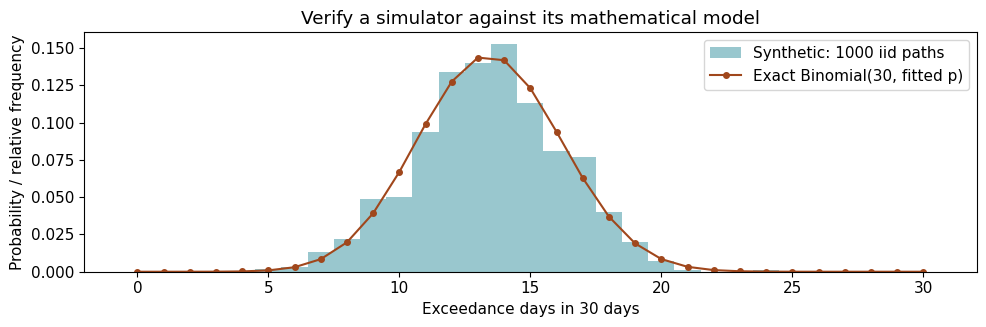

In [11]:
k = np.arange(N + 1)
fig, ax = plt.subplots()
ax.hist(totals, bins=np.arange(-0.5, N + 1.5), density=True,
        color="#77b5be", alpha=0.75, label=f"Synthetic: {REPS} iid paths")
ax.plot(k, binom.pmf(k, N, p_hat), "o-", color="#a0471c", ms=4,
        label="Exact Binomial(30, fitted p)")
ax.set(xlabel="Exceedance days in 30 days", ylabel="Probability / relative frequency",
       title="Verify a simulator against its mathematical model")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Validate on later observations
We now reveal September–December. The baseline predicts the same $\widehat p$ for each test day. The **Brier score** for $h$ held-out binary observations is

$$\operatorname{BS}=\frac1h\sum_{j=1}^{h}(y_j-\widehat p)^2.$$

Lower is better; zero is perfect. We also score an always-unflagged forecast, which assigns probability zero every day. This is a simple comparator on the same held-out outcome. An average score alone does not test whether a simulated temporal pattern resembles observations.

A complementary diagnostic is the number of changes of state,

$$K=\sum_{j=2}^{h}1\{Y_j\ne Y_{j-1}\},\qquad E[K]=2p(1-p)(h-1)\quad\text{under iid days}.$$

Neighboring switch indicators overlap in a shared day, so we do **not** assume $K$ is binomial. We use independent simulated paths to obtain its model distribution.

In [12]:
y_test = test["y"].to_numpy()
h = len(y_test)
observed_switches = int(np.count_nonzero(np.diff(y_test)))
expected_switches = 2 * p_hat * (1 - p_hat) * (h - 1)
brier = float(np.mean((y_test - p_hat) ** 2))
always_zero_brier = float(np.mean(y_test ** 2))
validation = pd.Series({"held-out days": h,
    "observed held-out exceedance rate": y_test.mean(), "fitted daily probability": p_hat,
    "Brier score, fitted probability": brier, "Brier score, always zero": always_zero_brier,
    "observed switches": observed_switches,
    "expected iid switches": expected_switches})
display(validation.to_frame("value"))

,value
held-out days,122.000000
observed held-out exceedance rate,0.393443
fitted daily probability,0.448560
"Brier score, fitted probability",0.241683
"Brier score, always zero",0.393443
observed switches,27.000000
expected iid switches,59.859642


The running rate after $j$ held-out days is $j^{-1}\sum_{i=1}^{j}y_i$. Its trajectory retains time order. We compare it to one synthetic held-out-length path and the constant fitted probability. A line that ends near the model mean can still wander in a systematically different way.

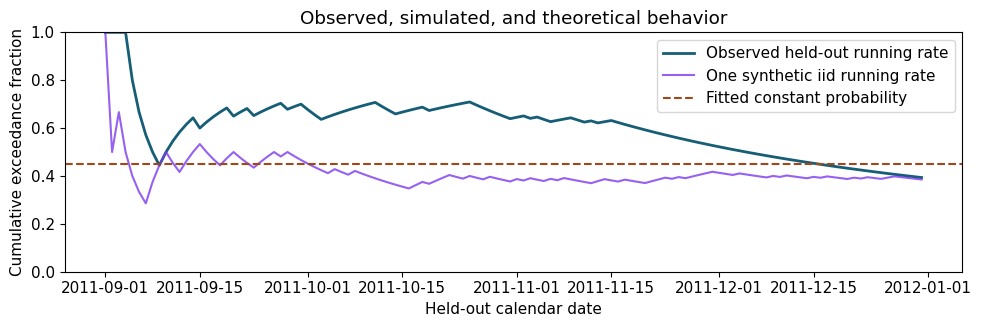

In [13]:
test_paths = simulate_iid(p_hat, h, REPS, seed=SEED + 1)
test_day = np.arange(1, h + 1)
fig, ax = plt.subplots()
ax.plot(test["dteday"], np.cumsum(y_test) / test_day,
        color="#155e75", lw=2, label="Observed held-out running rate")
ax.plot(test["dteday"], test_paths[0].cumsum() / test_day,
        color="#7c3aed", alpha=0.8, label="One synthetic iid running rate")
ax.axhline(p_hat, color="#a0471c", ls="--", label="Fitted constant probability")
ax.set(xlabel="Held-out calendar date", ylabel="Cumulative exceedance fraction", ylim=(0, 1),
       title="Observed, simulated, and theoretical behavior")
ax.legend()
fig.tight_layout()
plt.show()

The switch distribution below is conditional on the fitted probability. Its central 95% simulation range is a **model predictive range** for a path statistic, not a confidence interval for a fitted parameter. It excludes uncertainty about the fitted probability and model structure.

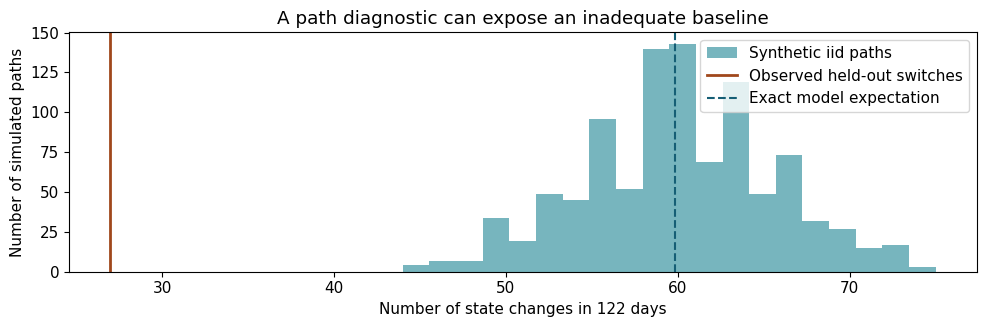

Central 95% simulated switch range, fitted model only: [49. 71.]


In [14]:
simulated_switches = np.count_nonzero(np.diff(test_paths, axis=1), axis=1)
switch_range = np.quantile(simulated_switches, [0.025, 0.975])
fig, ax = plt.subplots()
ax.hist(simulated_switches, bins=20, color="#77b5be", label="Synthetic iid paths")
ax.axvline(observed_switches, color="#a0471c", lw=2, label="Observed held-out switches")
ax.axvline(expected_switches, color="#155e75", ls="--", label="Exact model expectation")
ax.set(xlabel="Number of state changes in 122 days", ylabel="Number of simulated paths",
       title="A path diagnostic can expose an inadequate baseline")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Central 95% simulated switch range, fitted model only: {switch_range}")

Monthly rates help us interpret the mismatch. For each month with $h_m$ observed days, the constant model expects $h_m\widehat p$ exceedance days. This calculation uses the same frozen training estimate for every month; monthly test rates below are descriptive checks, not newly fitted predictions.

In [15]:
monthly = bike.groupby("mnth")["y"].agg(days="size", observed_exceedances="sum", observed_rate="mean")
monthly["expected_exceedances"] = monthly["days"] * p_hat
monthly["period"] = np.where(monthly.index < 9, "training", "held out")
display(monthly.round(3))

,days,observed_exceedances,observed_rate,expected_exceedances,period
mnth,,,,,
1,31,0,0.000,13.905,training
2,28,0,0.000,12.560,training
3,31,0,0.000,13.905,training
4,30,8,0.267,13.457,training
5,31,25,0.806,13.905,training
6,30,27,0.900,13.457,training
7,31,25,0.806,13.905,training
8,31,24,0.774,13.905,training
9,30,21,0.700,13.457,held out


The test exceedance fraction is around 0.39 versus the fitted probability around 0.45. The fitted model improves the Brier score relative to always assigning probability zero (about 0.24 versus 0.39), but there are only 27 observed switches versus about 60 expected under iid days. Months also differ substantially. A near-average fit does not validate the joint distribution. Seasonal changes, growth, weather, and serial dependence are plausible contributors; one year does not separate them.

**Interpretation:** We can verify that the code correctly simulates an iid model and simultaneously find that the model is a poor description of the observed paths. Increasing the number of simulations only sharpens the prediction of that same model.

## 5. Compare assumptions without calling them estimates
As a worked sensitivity analysis, consider $p$ at $\widehat p-0.10$, $\widehat p$, and $\widehat p+0.10$ (clipped to valid probabilities). These are **assumed scenarios**, not a confidence interval, a seasonal forecast, or a causal intervention.

For a reporting question about 20 or more exceedance days in the next 30 days,

$$P(S_{30}\ge20)=1-P(S_{30}\le19).$$

SciPy's survival function computes this upper tail directly. Remember that the binomial tail applies only under the iid model and a fixed $p$.

In [16]:
scenario_p = np.clip([p_hat - 0.10, p_hat, p_hat + 0.10], 0, 1)
scenarios = pd.DataFrame({"assumed p": scenario_p})
scenarios["expected exceedance days / 30"] = N * scenario_p
scenarios["probability at least 20 / 30"] = binom.sf(19, N, scenario_p)
scenarios.index = ["lower-p assumption", "fitted baseline", "higher-p assumption"]
display(scenarios.round(4))

,assumed p,expected exceedance days / 30,probability at least 20 / 30
lower-p assumption,0.3486,10.4568,0.0004
fitted baseline,0.4486,13.4568,0.0133
higher-p assumption,0.5486,16.4568,0.1316


Four distinct uncertainty concepts matter:

| Type | What varies? | Does increasing simulation paths resolve it? |
|---|---|---|
| Process variability | The next path even if the model and $p$ were known | No |
| Monte Carlo error | A finite numerical estimate of a model quantity | Yes, MCSE typically scales as $R^{-1/2}$ |
| Data/parameter uncertainty | The estimate of $p$ from limited observations | No; collect or model information |
| Model uncertainty | Constant probability, independence, and what was omitted | No; diagnose and compare models |

If the observations truly were iid Bernoulli, the plug-in standard error of $\widehat p$ would be $\sqrt{\widehat p(1-\widehat p)/m}$. The patterns here undermine that iid premise. Treating 243 dependent, changing days as exchangeable trials can understate uncertainty or miss changes in the mean. We therefore do not label the sensitivity scenarios as a calibrated interval.

## 6. Student exercises · complete in your own words
Submit your annotated notebook as the Module 1 portion of Concept Lab 1. Keep these answers brief: a small computation or plot plus 2–4 interpretive sentences per exercise. Worked results above are examples; the tasks below are intentionally unanswered.

**Exercise 1 — Identify the object.** State the time index and state space for $Y_t$ and $S_n$. Explain the distinction between one observed path, 1,000 independent simulated paths, and 1,000 independent observed years. Is the daily mean $\widehat p$ itself a possible state? What extra information beyond daily marginal probabilities is needed to define a process?

**Your response:** _Write here._

**Exercise 2 — Monte Carlo precision.** Before running, predict the change in MCSE when `REPS` grows from 250 to 4,000 with $n=30$ and $p=\widehat p$. Use seeds 6231 and 6232 at each replication count; compare the simulated mean, exact mean, theoretical process SD, and MCSE. Explain why a particular larger run is not guaranteed to have a smaller absolute mean error. Do not change the fitted probability.

In [17]:
# Your computation for Exercise 2.
# Reuse simulate_iid and the formulas above; leave the worked-example variables intact.

**Your interpretation:** _Write here._

**Exercise 3 — A held-out check with units.** Divide the first 120 test days into four nonoverlapping blocks of 30 days and compute their exceedance totals; explicitly report why two days are unused. Compare these four totals with the fitted Binomial$(30,\widehat p)$ distribution. Explain why four blocks are too few to establish a stable distribution and why shuffling the test days would change the question. State one additional measured variable that might support a better next model. Do not refit on the test period.

In [18]:
# Your computation for Exercise 3.
# y_test is in chronological order; labels should identify observed vs synthetic quantities.

**Your interpretation:** _Write here._

**Exercise 4 — AI verification, no AI account required.** Treat the following proposed code as an unverified assistant response. It claims to generate one 30-day iid Bernoulli path:

```python
rng = np.random.default_rng(6231)
path = np.repeat(rng.binomial(1, p_hat), 30)
```

Audit the claim: check valid probabilities and units, limiting cases $p=0,1$, the mean of the total, its variance, and dependence within a path. Explain which checks can pass even if the claim is wrong. Repair the code and provide one decisive empirical comparison with a known formula. You may use an AI tool to discuss your reasoning, but it is optional and you must verify any output yourself.

In [19]:
# Your audit and repair for Exercise 4.
# Use independent repetitions when estimating the distribution of a path total.

**Your explanation and verification evidence:** _Write here._

### Optional extension · changing thresholds
Compare scenario thresholds 3,000 and 5,000 rentals/day. For each threshold, rederive the training indicator, refit only on January–August, and report the test Brier score and switch comparison. Thresholds define different outcomes; their scores are not a fair competition to select a universally "best" threshold. Explain what real decision and units would justify choosing a threshold before analysis. No causal claim about adding bikes or capacity follows from this exercise.

### Responsible AI and reproducibility record
Complete this even if no AI tool was used:

- **Consequential assistance:** _None, or tool/version/date and what it helped produce._
- **Verification performed:** _Analytical checks, data checks, or empirical comparisons you performed yourself._
- **My explanation:** _One assumption you can defend and one you would revise before a decision._
- **Changes from the starter:** _Thresholds, seeds, parameters, or code changed._

Be ready to explain, modify, and defend all submitted code. Do not upload private project data to an assistant without authorization. Copying a claim is not a mathematical or empirical check.

## Reproducibility information
The bundled source hash is checked above. The cell below records the environment used for this run. Numerical random streams can depend on the library version; the seed is one part of reproducibility. Our next module replaces independent days with a finite-state model and asks whether conditioning on the current state improves prediction. That model will also need validation.

In [20]:
versions = {name: metadata.version(name) for name in
            ["numpy", "pandas", "scipy", "matplotlib", "nbformat", "nbclient", "ipykernel"]}
print("Python", platform.python_version())
print(json.dumps(versions, indent=2))
print("Seed:", SEED)
print("CSV SHA-256:", source["sample_sha256"])

Python 3.10.9
{
  "numpy": "1.24.2",
  "pandas": "2.0.0",
  "scipy": "1.10.1",
  "matplotlib": "3.7.1",
  "nbformat": "5.7.0",
  "nbclient": "0.5.13",
  "ipykernel": "6.19.2"
}
Seed: 6231
CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
